In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:

adult_data = pd.read_csv('/content/adult_dataset.csv')

In [10]:
adult_data.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [67]:
corr = adult_data.corr()


In [11]:
adult_data.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='object')

In [12]:
adult_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


In [13]:
adult_data.duplicated().sum()

np.int64(16)

In [14]:
adult_data.isnull().sum()

,0
age,2442
workclass,3362
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,3357
relationship,0
race,0
sex,0


In [15]:

# missing value handling

In [16]:
adult_data.isna().sum()/len(adult_data)*100  #percentage

,0
age,4.999795
workclass,6.883420
fnlwgt,0.000000
education,0.000000
education-num,0.000000
marital-status,0.000000
occupation,6.873183
relationship,0.000000
race,0.000000
sex,0.000000


In [17]:

adult_data.dtypes

,0
age,float64
workclass,object
fnlwgt,int64
education,object
education-num,int64
marital-status,object
occupation,object
relationship,object
race,object
sex,object


In [18]:

#missing value handling \ numerical
adult_data['age'] = adult_data['age'].fillna(adult_data['age'].median())
adult_data['hours-per-week'] = adult_data['hours-per-week'].fillna(adult_data['hours-per-week'].median())


In [19]:
#missing value handling \ categorical
adult_data['workclass'] = adult_data['workclass'].fillna(adult_data['workclass'].mode()[0])
adult_data['occupation'] = adult_data['occupation'].fillna(adult_data['occupation'].mode()[0])
adult_data['native-country'] = adult_data['native-country'].fillna(adult_data['native-country'].mode()[0])

In [20]:
adult_data.isna().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


# outlier handling

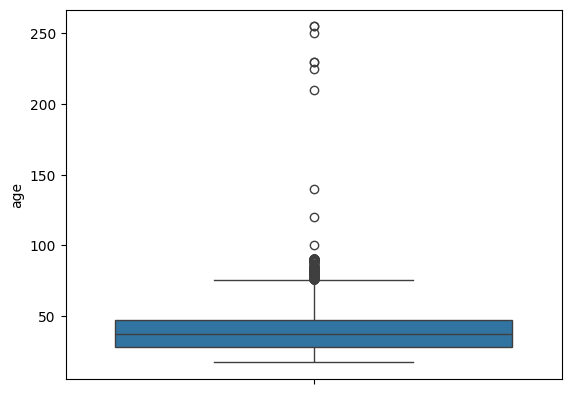

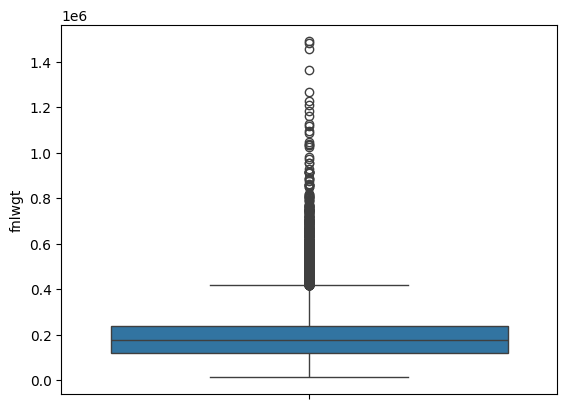

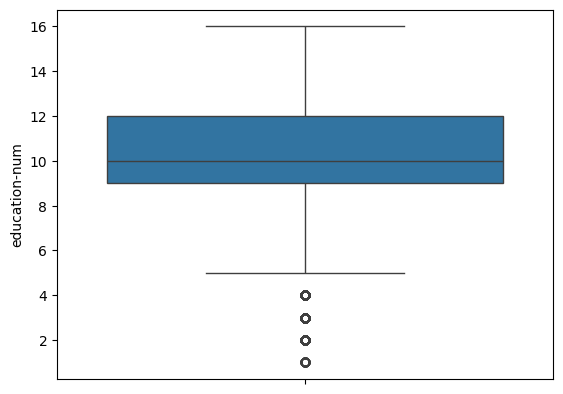

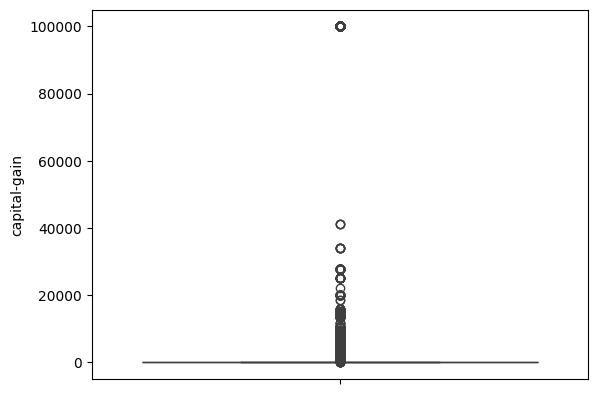

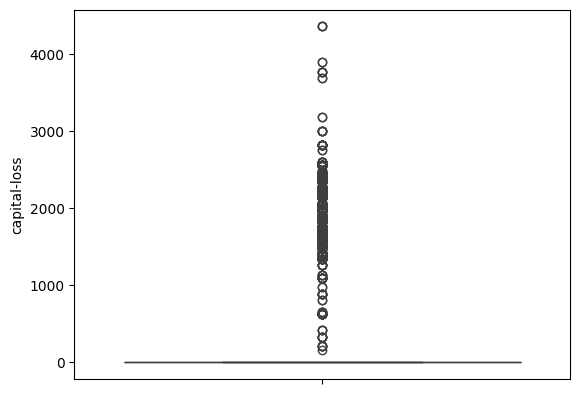

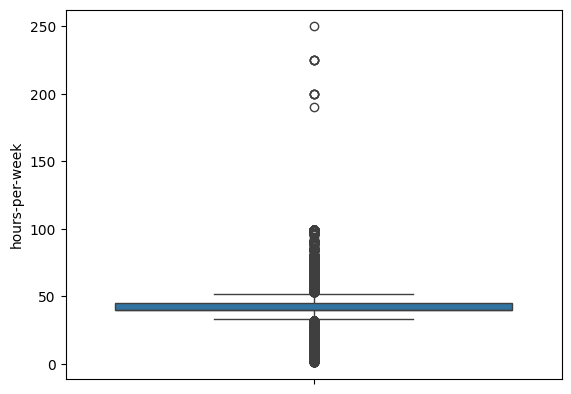

In [21]:
sns.boxplot(adult_data['age'])
plt.show()
sns.boxplot(adult_data['fnlwgt'])
plt.show()
sns.boxplot(adult_data['education-num'])
plt.show()
sns.boxplot(adult_data['capital-gain'])
plt.show()
sns.boxplot(adult_data['capital-loss'])
plt.show()
sns.boxplot(adult_data['hours-per-week'])
plt.show()

# outlier handling

In [22]:
q1 = adult_data['age'].quantile(0.25)
q2 = adult_data['age'].quantile(0.50)
q3 = adult_data['age'].quantile(0.75)

print(f'Q1 = {q1}\nQ2 = {q2}\nQ3 = {q3}')

IQR = q3-q1

up_limit = q3 + 1.5*IQR
low_limit = q1 - 1.5*IQR



print(f'IQR = {IQR}\nUp_limit = {up_limit}\nLow_limit = {low_limit}')




Q1 = 28.0
Q2 = 37.0
Q3 = 47.0
IQR = 19.0
Up_limit = 75.5
Low_limit = -0.5


In [23]:
adult_data.loc[adult_data['age']<low_limit,'age'] = low_limit
adult_data.loc[adult_data['age']>up_limit,'age'] = up_limit

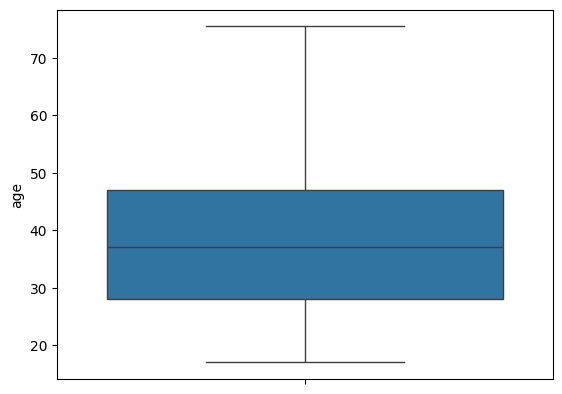

In [24]:
sns.boxplot(adult_data['age'])
plt.show()

In [25]:
adult_data.loc[adult_data['fnlwgt'] > 100000,'fnlwgt'] = 100000

In [26]:
q1 = adult_data['hours-per-week'].quantile(0.25)
q2 = adult_data['hours-per-week'].quantile(0.50)
q3 = adult_data['hours-per-week'].quantile(0.75)

IQR = q3-q1

up_limit = q3 + 1.5*IQR

low_limit = q1 - 1.5*IQR


print(f'IQR = {IQR}\nlow_limit = {low_limit}\nup_limit ={up_limit}')

IQR = 5.0
low_limit = 32.5
up_limit =52.5


In [27]:
adult_data.loc[ adult_data['hours-per-week'] > up_limit,'hours-per-week'] = up_limit

adult_data.loc[ adult_data['hours-per-week'] < low_limit,'hours-per-week'] = low_limit




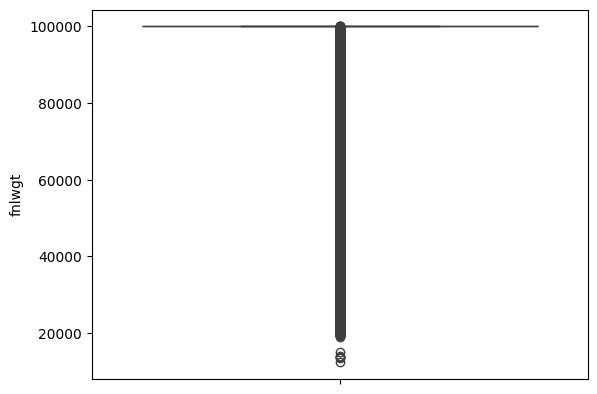

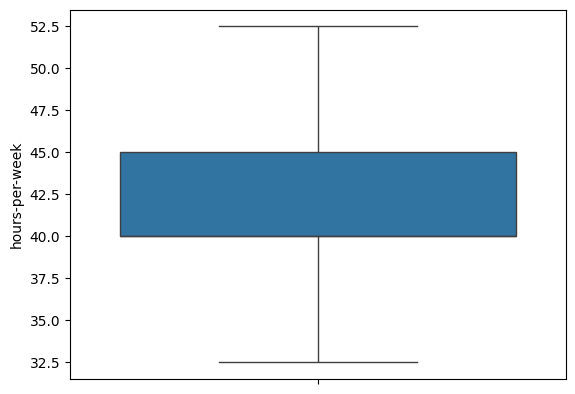

In [28]:
sns.boxplot(adult_data['fnlwgt'])
plt.show()
sns.boxplot(adult_data['hours-per-week'])
plt.show()

In [29]:
#encoding


In [30]:
adult_data.head(2)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,United-States,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,32.5,United-States,<=50K


In [31]:
adult_data.dtypes

,0
age,float64
workclass,object
fnlwgt,int64
education,object
education-num,int64
marital-status,object
occupation,object
relationship,object
race,object
sex,object


In [32]:
cat_cols =adult_data.select_dtypes(include= ['object'])
cat_cols

,workclass,education,marital-status,occupation,relationship,race,sex,native-country,income
0,State-gov,Bachelors,Never-married,Adm-clerical,Not-in-family,White,Male,United-States,<=50K
1,Self-emp-not-inc,Bachelors,Married-civ-spouse,Exec-managerial,Husband,White,Male,United-States,<=50K
2,Private,HS-grad,Divorced,Handlers-cleaners,Not-in-family,White,Male,United-States,<=50K
3,Private,11th,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,United-States,<=50K
4,Private,Bachelors,Married-civ-spouse,Prof-specialty,Wife,Black,Female,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...
48837,Private,Bachelors,Divorced,Prof-specialty,Not-in-family,White,Female,United-States,<=50K.
48838,Private,HS-grad,Widowed,Prof-specialty,Other-relative,Black,Male,United-States,<=50K.
48839,Private,Bachelors,Married-civ-spouse,Prof-specialty,Husband,White,Male,United-States,<=50K.
48840,Private,Bachelors,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,United-States,<=50K.


In [33]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
adult_data['income']= le.fit_transform(adult_data['income'])

In [34]:
adult_data.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,United-States,0
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,32.5,United-States,0
2,38.0,Private,100000,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,0
3,53.0,Private,100000,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,0
4,28.0,Private,100000,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,0


In [35]:
adult_data= pd.get_dummies(adult_data, dtype = int, drop_first= True)

In [36]:
x=adult_data.drop('income', axis=1)

In [37]:
adult_data.head()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,income,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39.0,77516,13,2174,0,40.0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,50.0,83311,13,0,0,32.5,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,38.0,100000,9,0,0,40.0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,53.0,100000,7,0,0,40.0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
4,28.0,100000,13,0,0,40.0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [38]:
#k means clustering
from sklearn.cluster import KMeans

wcss = []
for i in range(3,9):
  kmeans =KMeans(n_clusters=i, init= 'k-means++', random_state=42)
  kmeans.fit(x)
  wcss.append(kmeans.inertia_)

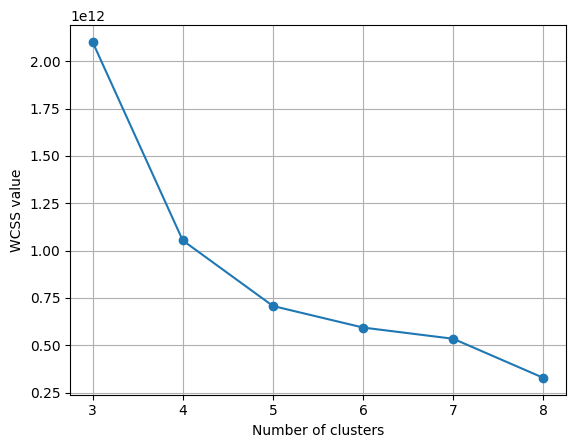

In [39]:
plt.plot(range(3,9),wcss,'o-')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS value')
plt.grid()

In [40]:
# elbow is appearing at k=4
# we can create kmeans model with no. of clusters=4

kmeans1 = KMeans(n_clusters=4, init='k-means++', random_state=42)
y_kmeans = kmeans1.fit_predict(x)

print(y_kmeans)

[1 1 0 ... 0 0 0]


In [41]:
#silhoutte score for kmean clustering

from sklearn.metrics import silhouette_score
sil_kmeans =  silhouette_score(x,y_kmeans)
print(sil_kmeans)

0.8875534685112666


In [42]:
x_sample = x.sample(n=10000, random_state=42).copy()

In [43]:
#agglomerative hierarchichal clustering

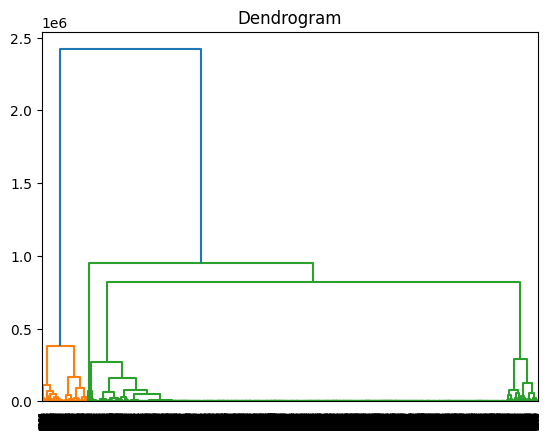

In [44]:
# using dentrogram to find the optimum number of clusters
import scipy.cluster.hierarchy as sch

dentrogram = sch.dendrogram(sch.linkage(x_sample,method='ward'))
plt.title('Dendrogram')
plt.show()

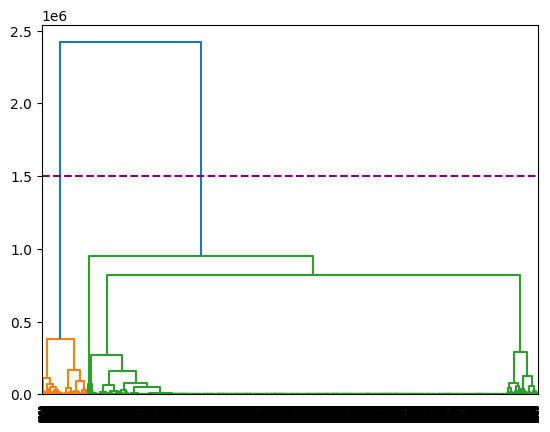

In [45]:
dentrogram = sch.dendrogram(sch.linkage(x_sample,method='ward'))
plt.axhline(y=1500000,color='purple',linestyle='--')

In [46]:
from sklearn.cluster import AgglomerativeClustering
hc = AgglomerativeClustering(n_clusters=2, linkage = 'ward')
y_hc = hc.fit_predict(x_sample)

In [47]:
silhoutte_avg =  silhouette_score(x_sample,y_hc)
print(silhoutte_avg )

0.8811424851880092


#DBSCAN

In [58]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import AgglomerativeClustering, DBSCAN

In [59]:
x, y = make_blobs(
    n_samples=400,
    cluster_std=0.08,
    random_state=42
)

In [60]:
models = [
    ("Agglomerative", AgglomerativeClustering(n_clusters=2)),
    ("DBSCAN", DBSCAN(eps=0.5, min_samples=6))
]

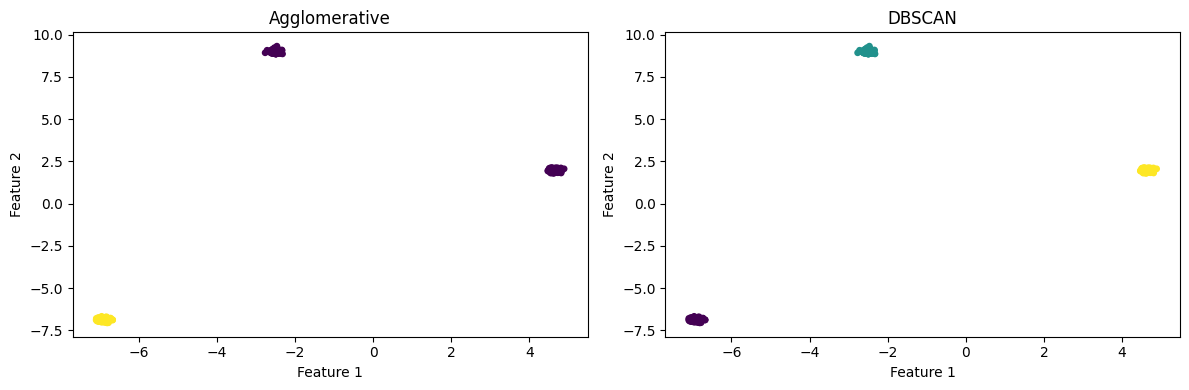

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, model) in zip(axes, models):
    labels = model.fit_predict(x)
    ax.scatter(x[:, 0], x[:, 1], c=labels, cmap="viridis", s=15)
    ax.set_title(name)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()
